# 05 — Segmentation, Targeting & Pilot Design

**Stages 4–6 of the Tier A pipeline, adapted to an unsupervised problem.** There is no target variable,
so "evaluation" means: is the structure stronger than chance, is it stable, can it be written as a rule
a CRM team can run, and is it fair? Then the segmentation is turned into a decision: whom to retain,
whom to try to convert, and how large a pilot must be to prove the conversion is real (**Path C,
prospective**: an experiment design, not an estimate).

| § | Issue-tree branch | Question |
|---|---|---|
| 5.1 | B | Which features? |
| 5.2 | B1 | How many segments — and is that stronger than data with no structure? |
| 5.3–5.4 | B2 | What are they, and do they survive seeds, algorithms and resampling? |
| 5.5 | B3 | Can a two-threshold rule replace the model? |
| 5.6 | A | How does the pair construction show up in the segments? |
| 5.7 | D1–D2 | Whom to retain, whom to convert? |
| 5.8 | — | Fairness: gender and age |
| 5.9 | D3 | How big must a conversion pilot be? |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
while not (ROOT / "archive" / "Mall_Customers.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARCHIVE = ROOT / "archive"
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS, MODELS = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "models"
for p in (RAW, PROC, REPORTS, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

KF_PATH = REPORTS / "_key_figures.json"


def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if hasattr(v, "item"):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    return v


def kf_update(**kw):
    """Append to reports/_key_figures.json — the only place the report reads numbers from."""
    kf = json.loads(KF_PATH.read_text()) if KF_PATH.exists() else {}
    kf.update({k: _plain(v) for k, v in kw.items()})
    KF_PATH.write_text(json.dumps(kf, indent=1, sort_keys=True))
    print(f"  _key_figures.json <- {', '.join(kw)}  ({len(kf)} figures total)")

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#008A7E,#C1841C,#00A9F4" --mode light --pairs all
#     PASS lightness | PASS chroma floor | PASS CVD separation (worst pair dE 12.5 protan)
#     PASS normal-vision separation (18.3) | WARN contrast: Cyan 2.56:1 on white
# The Cyan WARN obliges relief: every segment is direct-labelled AND has its own marker shape,
# and the report carries the profile as a table. DESIGN.md's Teal #00857C FAILS the chroma floor
# (C = 0.097 < 0.10, reads as grey), so it is nudged to #008A7E on the same hue.
# Grey is context ink only (the Mainstream segment); Navy is text ink only — never a series fill.
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER, CYAN = "#051C2C", "#2251FF", "#008A7E", "#C1841C", "#00A9F4"
SLATE, GREY, GRID, LIGHT = "#7F93A6", "#9FADB8", "#E9ECEF", "#D5DCE2"

# Semantic mapping, fixed once and used in every notebook (fixed order Blue → Teal → Amber → Cyan):
SEGMENTS = ["Under-engaged Affluent", "Affluent Spenders", "Young Enthusiasts",
            "Budget Conscious", "Mainstream"]
SEG_COLORS = {"Under-engaged Affluent": BLUE,    # the conversion question — the emphasis story
              "Affluent Spenders": TEAL,         # the core to retain
              "Young Enthusiasts": AMBER,
              "Budget Conscious": CYAN,
              "Mainstream": GREY}                # context
SEG_MARKERS = {"Under-engaged Affluent": "o", "Affluent Spenders": "s", "Young Enthusiasts": "^",
               "Budget Conscious": "D", "Mainstream": "."}
C_FOCUS, C_SECOND, C_REF, C_CONTEXT = BLUE, TEAL, AMBER, GREY


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
SOURCE = "Mall_Customers.csv (Kaggle 'Mall Customer Segmentation Data', 200 loyalty members)"


def finish(fig, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3. Placed under the lowest
    artist (axis labels, outside legends), so it never collides with them."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    y0 = min(ax.get_tightbbox(r).transformed(fig.transFigure.inverted()).y0 for ax in fig.axes)
    fig.text(0.005, y0 - 0.12 / fig.get_figheight(), f"Source: {SOURCE}" + (f" · {note}" if note else ""),
             fontsize=7, color=SLATE, ha="left", va="top")


def suptitle(fig, text, y=1.04):
    fig.suptitle(text, x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=y)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score, StratifiedKFold
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

df = pd.read_parquet(PROC / "mall_clean.parquet")
rng = np.random.default_rng(RANDOM_STATE)
FEATURES = ["income_k", "score"]
assert "customer_id" not in FEATURES and "id_odd" not in FEATURES and "pair_id" not in FEATURES
scaler = StandardScaler().fit(df[FEATURES])
X = scaler.transform(df[FEATURES])
print(f"{len(df)} members · features {FEATURES} (standardised)")

200 members · features ['income_k', 'score'] (standardised)


## 5.1 Feature set — income and score; age is a descriptor

The review clusters on income and score. The alternative is to add age. Same procedure on both:

In [2]:
X3 = StandardScaler().fit_transform(df[["age", "income_k", "score"]])
feat_cmp = pd.DataFrame({
    "income + score": [silhouette_score(X, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)) for k in range(2, 9)],
    "age + income + score": [silhouette_score(X3, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X3)) for k in range(2, 9)],
}, index=range(2, 9)).round(3)
feat_cmp.index.name = "k"
print(feat_cmp.T)
best3 = feat_cmp["age + income + score"].max()

k                         2      3      4      5      6      7      8
income + score        0.321  0.467  0.494  0.555  0.540  0.528  0.455
age + income + score  0.335  0.358  0.404  0.417  0.428  0.417  0.408


Adding age gives a worse silhouette at every k (best ~0.43 against 0.555), and its segments would be
harder to act on: age is a continuous gradient with one hard edge (the ceiling at 40, `04` §4.3), not
a set of separate clusters. So the segmentation uses income and score, and age profiles the segments
afterwards. Nothing derived from `CustomerID` is used.

## 5.2 How many segments — against a null with no structure

A silhouette of 0.555 only means something next to what clustering finds in data with *no* segments.
Two nulls, 100 draws each, same k-means settings:

- **Uniform box**: points spread evenly over the same standardised range.
- **Independence**: the real income and the real score values, shuffled against each other (same
  marginals, no joint structure).

In [3]:
K = range(2, 9)
fits = {k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X) for k in K}
crit = pd.DataFrame({
    "inertia": [fits[k].inertia_ for k in K],
    "silhouette": [silhouette_score(X, fits[k].labels_) for k in K],
    "calinski_harabasz": [calinski_harabasz_score(X, fits[k].labels_) for k in K],
    "davies_bouldin": [davies_bouldin_score(X, fits[k].labels_) for k in K],
    "gmm_bic": [GaussianMixture(k, n_init=5, random_state=RANDOM_STATE).fit(X).bic(X) for k in K],
}, index=list(K))

null_unif, null_perm = {k: [] for k in K}, {k: [] for k in K}
for b in range(100):
    U = rng.uniform(X.min(0), X.max(0), size=X.shape)
    P = np.column_stack([X[:, 0], rng.permutation(X[:, 1])])
    for k in K:
        null_unif[k].append(silhouette_score(U, KMeans(k, n_init=3, random_state=b).fit_predict(U)))
        null_perm[k].append(silhouette_score(P, KMeans(k, n_init=3, random_state=b).fit_predict(P)))
crit["null_uniform_p97.5"] = [np.percentile(null_unif[k], 97.5) for k in K]
crit["null_indep_p97.5"] = [np.percentile(null_perm[k], 97.5) for k in K]
crit["null_max_any"] = [max(max(null_unif[k]), max(null_perm[k])) for k in K]
winners = {"silhouette": crit.silhouette.idxmax(), "calinski_harabasz": crit.calinski_harabasz.idxmax(),
           "davies_bouldin": crit.davies_bouldin.idxmin(), "gmm_bic": crit.gmm_bic.idxmin()}
print("k chosen by each criterion:", winners)
crit.round(3)

k chosen by each criterion: {'silhouette': np.int64(5), 'calinski_harabasz': np.int64(8), 'davies_bouldin': np.int64(5), 'gmm_bic': np.int64(5)}


,inertia,silhouette,calinski_harabasz,davies_bouldin,gmm_bic,null_uniform_p97.5,null_indep_p97.5,null_max_any
2,269.691,0.321,95.669,1.267,1148.473,0.443,0.351,0.447
3,157.704,0.467,151.335,0.716,1151.718,0.431,0.375,0.457
4,108.921,0.494,174.595,0.710,1079.494,0.441,0.387,0.446
5,65.568,0.555,248.649,0.572,1058.652,0.432,0.403,0.442
6,55.057,0.540,243.088,0.655,1071.567,0.427,0.424,0.451
7,44.865,0.528,254.621,0.715,1085.590,0.430,0.419,0.444
8,37.228,0.455,267.279,0.760,1082.480,0.425,0.417,0.432


### Exhibit 6 — Five segments, and far stronger than chance: silhouette 0.555 against at most ~0.44 from data with no segments

Calinski–Harabasz gain per extra segment: {3: 55.7, 4: 23.3, 5: 74.1, 6: -5.6, 7: 11.5, 8: 12.7}


  saved reports/figures/ex06_k_selection.png


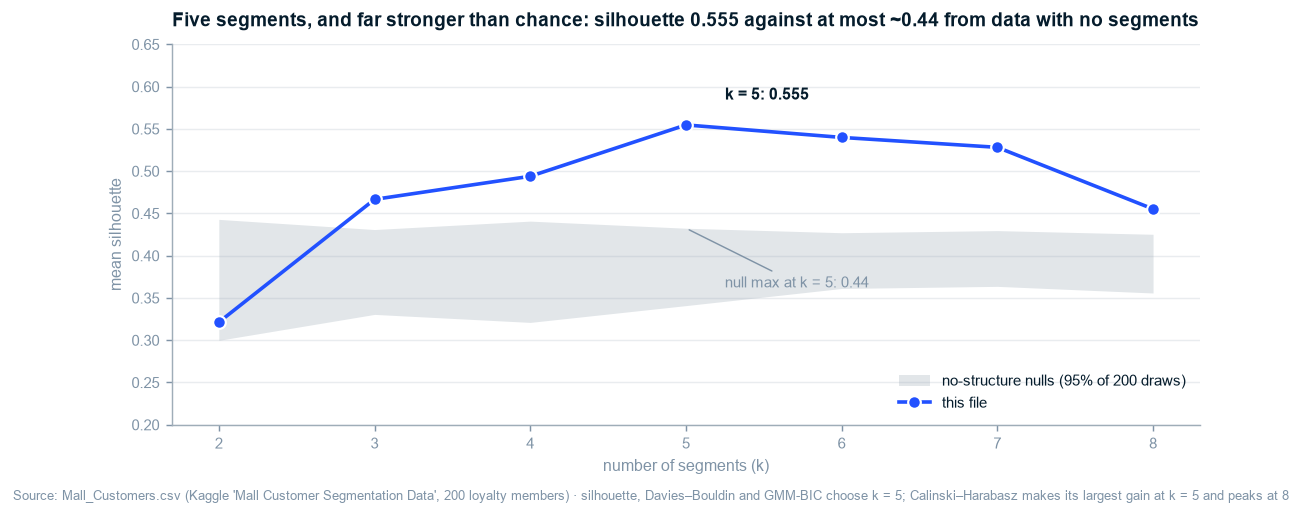

In [4]:
K_STAR = 5
assert winners["silhouette"] == winners["davies_bouldin"] == winners["gmm_bic"] == K_STAR, winners
ch_gain = crit.calinski_harabasz.diff()
assert ch_gain.idxmax() == K_STAR           # CH's largest single gain is the step to k = 5
print("Calinski–Harabasz gain per extra segment:", ch_gain.round(1).dropna().to_dict())
fig, ax = plt.subplots(figsize=(10.2, 3.8))
ks = np.array(list(K))
lo = np.minimum([np.percentile(null_unif[k], 2.5) for k in K], [np.percentile(null_perm[k], 2.5) for k in K])
hi = np.maximum([np.percentile(null_unif[k], 97.5) for k in K], [np.percentile(null_perm[k], 97.5) for k in K])
ax.fill_between(ks, lo, hi, color=GREY, alpha=0.30, lw=0, label="no-structure nulls (95% of 200 draws)")
ax.plot(ks, crit.silhouette, color=BLUE, marker="o", ms=7, mec="white", mew=1.2, label="this file")
ax.annotate(f"k = 5: {crit.silhouette[5]:.3f}", (5, crit.silhouette[5]), xytext=(5.25, crit.silhouette[5] + 0.03),
            fontsize=9, color=NAVY, fontweight="bold")
ax.annotate(f"null max at k = 5: {crit.null_max_any[5]:.2f}", (5, hi[3]), xytext=(5.25, hi[3] - 0.07),
            fontsize=8.5, color=SLATE, arrowprops=dict(arrowstyle="-", color=SLATE, lw=0.8))
ax.set_xticks(ks); ax.set_xlabel("number of segments (k)"); ax.set_ylabel("mean silhouette")
ax.set_ylim(0.2, 0.65)
ax.legend(loc="lower right")
ax.set_title("Five segments, and far stronger than chance: silhouette 0.555 against at most ~0.44 from data with no segments")
finish(fig, "silhouette, Davies–Bouldin and GMM-BIC choose k = 5; Calinski–Harabasz makes its largest gain at k = 5 and peaks at 8")
save(fig, "ex06_k_selection.png")
plt.show()

**So What:** silhouette, Davies–Bouldin and the mixture-model BIC all choose five. Calinski–Harabasz,
which tends to favour more clusters, makes its largest gain at the step to five (+74) and then creeps up
by at most 13 per step to a peak at eight, so it does not argue for a different answer. At k = 5 the real silhouette clears the best of 200
no-structure draws by more than 0.1. The segments are a feature of the data, not something k-means
imposes on any cloud of points.

**Implication:** marketing can treat "five segments" as settled for this file. The open questions are
what the segments are and how big they really are, not how many there are.

## 5.3 The five segments

Cluster numbers are arbitrary, so segments are named by where their centre sits on the income and score
thresholds fixed in `02` (income ≤ 40 / ≥ 70k, score ≤ 40 / ≥ 60), never by label number.

In [5]:
km = KMeans(K_STAR, n_init=10, random_state=RANDOM_STATE).fit(X)
cent = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEATURES)


def name_of(c):
    hi_i, lo_i = c.income_k >= 70, c.income_k <= 40
    hi_s, lo_s = c.score >= 60, c.score <= 40
    if hi_i and lo_s: return "Under-engaged Affluent"
    if hi_i and hi_s: return "Affluent Spenders"
    if lo_i and hi_s: return "Young Enthusiasts"
    if lo_i and lo_s: return "Budget Conscious"
    return "Mainstream"


cent["segment"] = [name_of(c) for _, c in cent.iterrows()]
assert sorted(cent.segment) == sorted(SEGMENTS), "segment naming is not one-to-one"
df["segment"] = pd.Categorical(cent.segment.to_numpy()[km.labels_], categories=SEGMENTS)
df["silhouette"] = silhouette_samples(X, km.labels_)
df["dist_to_centroid"] = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)

profile = df.groupby("segment", observed=True).agg(
    n=("customer_id", "size"), income_mean=("income_k", "mean"), score_mean=("score", "mean"),
    age_median=("age", "median"), age_min=("age", "min"), age_max=("age", "max"),
    share_age_le_40=("age_over_40", lambda s: 1 - s.mean()), female=("gender_female", "mean"),
    spending_gap=("spending_gap", "mean"), silhouette=("silhouette", "mean"))
profile["share"] = profile.n / len(df)
profile.round(2)

,n,income_mean,score_mean,age_median,age_min,age_max,share_age_le_40,female,spending_gap,silhouette,share
segment,,,,,,,,,,,
Under-engaged Affluent,35,88.20,17.11,42.0,19,59,0.43,0.46,-0.68,0.51,0.18
Affluent Spenders,39,86.54,82.13,32.0,27,40,1.00,0.54,0.05,0.51,0.20
Young Enthusiasts,22,25.73,79.36,23.5,18,35,1.00,0.59,0.72,0.60,0.11
Budget Conscious,23,26.30,20.91,46.0,19,67,0.39,0.61,0.05,0.51,0.12
Mainstream,81,55.30,49.52,46.0,18,70,0.46,0.59,0.06,0.60,0.40


The review's table reproduces exactly (n = 39 / 22 / 81 / 35 / 23, same centres). Two things it did
not show: every Affluent Spender is aged 27–40, and the Under-engaged Affluent are split almost evenly
either side of 40 (§5.7).

## 5.4 Robustness — seeds, algorithms, resampling, outliers

In [6]:
seed_ari = [adjusted_rand_score(km.labels_, KMeans(K_STAR, n_init=10, random_state=s).fit_predict(X)) for s in range(50)]
single = [adjusted_rand_score(km.labels_, KMeans(K_STAR, n_init=1, random_state=s).fit_predict(X)) for s in range(200)]
gmm = GaussianMixture(K_STAR, n_init=5, random_state=RANDOM_STATE).fit(X)
ari_gmm = adjusted_rand_score(km.labels_, gmm.predict(X))
ari_ward = adjusted_rand_score(km.labels_, AgglomerativeClustering(K_STAR, linkage="ward").fit_predict(X))
df["gmm_confidence"] = gmm.predict_proba(X).max(axis=1)

# Bootstrap (Hennig-style): refit on a resample, assign everyone, best Jaccard match per original segment.
J = np.zeros((200, K_STAR))
for b in range(200):
    idx = rng.integers(0, len(X), len(X))
    lb = KMeans(K_STAR, n_init=10, random_state=b).fit(X[idx]).predict(X)
    for c in range(K_STAR):
        A = km.labels_ == c
        J[b, c] = max((A & (lb == d)).sum() / (A | (lb == d)).sum() for d in range(K_STAR))
jac = pd.DataFrame({"segment": cent.segment, "jaccard_mean": J.mean(0), "jaccard_p5": np.percentile(J, 5, axis=0)})

keep = ~df.income_outlier.to_numpy()
lab_wo = KMeans(K_STAR, n_init=10, random_state=RANDOM_STATE).fit(X[keep]).labels_
ari_wo_outliers = adjusted_rand_score(km.labels_[keep], lab_wo)
ari_quadrant = adjusted_rand_score(km.labels_, df.income_quadrant)

robust = pd.DataFrame([
    ("50 seeds, n_init = 10", f"ARI min {min(seed_ari):.3f}", "identical every time"),
    ("200 seeds, n_init = 1", f"{np.mean(np.array(single) < 0.99):.0%} of runs land elsewhere", "a single start is unsafe: always use n_init ≥ 10"),
    ("Gaussian mixture (k = 5)", f"ARI {ari_gmm:.3f}", "same segments, different algorithm"),
    ("Ward hierarchical (k = 5)", f"ARI {ari_ward:.3f}", "same segments, different algorithm"),
    ("200 bootstrap refits", f"Jaccard {jac.jaccard_mean.min():.2f}–{jac.jaccard_mean.max():.2f}", "every segment ≥ 0.85 = highly stable"),
    ("drop 2 income outliers (137k)", f"ARI {ari_wo_outliers:.3f}", "tail does not drive the result"),
    ("median-split quadrants (baseline)", f"ARI {ari_quadrant:.3f}", "the naive 2×2 misses the structure"),
    ("members with silhouette < 0.25", f"{(df.silhouette < 0.25).sum()} of {len(df)}", "borderline — flagged, not reassigned"),
], columns=["check", "result", "reading"])
print(jac.round(3).to_string(index=False))
robust

               segment  jaccard_mean  jaccard_p5
            Mainstream         0.973       0.940
     Affluent Spenders         1.000       1.000
     Young Enthusiasts         0.986       0.955
Under-engaged Affluent         0.969       0.921
      Budget Conscious         0.969       0.913


,check,result,reading
0,"50 seeds, n_init = 10",ARI min 1.000,identical every time
1,"200 seeds, n_init = 1",42% of runs land elsewhere,a single start is unsafe: always use n_init ≥ 10
2,Gaussian mixture (k = 5),ARI 0.956,"same segments, different algorithm"
3,Ward hierarchical (k = 5),ARI 0.942,"same segments, different algorithm"
4,200 bootstrap refits,Jaccard 0.97–1.00,every segment ≥ 0.85 = highly stable
5,drop 2 income outliers (137k),ARI 0.985,tail does not drive the result
6,median-split quadrants (baseline),ARI 0.393,the naive 2×2 misses the structure
7,members with silhouette < 0.25,11 of 200,"borderline — flagged, not reassigned"


The segments are stable on every axis checked. The one fragility is procedural: a single k-means
start lands on a different solution in a large share of runs. Anyone re-running this must keep
`n_init ≥ 10`, which the segmentation card records.

## 5.5 From model to rule — two thresholds CRM can run without a model

The thresholds were fixed in `02` *before* clustering, so this agreement check is not circular.

In [7]:
def grid_rule(income, score):
    return np.select(
        [(income >= 70) & (score <= 40), (income >= 70) & (score >= 60),
         (income <= 40) & (score >= 60), (income <= 40) & (score <= 40)],
        ["Under-engaged Affluent", "Affluent Spenders", "Young Enthusiasts", "Budget Conscious"], "Mainstream")


df["segment_rule"] = grid_rule(df.income_k.to_numpy(), df.score.to_numpy())
agree = (df.segment_rule == df.segment.astype(str)).mean()
ari_rule = adjusted_rand_score(df.segment.astype(str), df.segment_rule)
print(f"two-threshold rule agrees with k-means on {agree:.1%} of members (ARI {ari_rule:.3f})")
print(pd.crosstab(df.segment, df.segment_rule).to_string())
print("\ndisagreements:")
print(df.loc[df.segment_rule != df.segment.astype(str), ["customer_id", "income_k", "score", "segment", "segment_rule", "silhouette"]].round(2).to_string(index=False))

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
tree_acc = {d: cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE),
                               df[FEATURES], df.segment.astype(str), cv=cv).mean() for d in (2, 3, 4)}
print("\ndecision tree, 5-fold CV accuracy by depth:", {d: round(v, 3) for d, v in tree_acc.items()})

two-threshold rule agrees with k-means on 97.5% of members (ARI 0.926)
segment_rule            Affluent Spenders  Budget Conscious  Mainstream  Under-engaged Affluent  Young Enthusiasts
segment                                                                                                           
Under-engaged Affluent                  0                 0           0                      35                  0
Affluent Spenders                      38                 0           1                       0                  0
Young Enthusiasts                       0                 0           0                       0                 22
Budget Conscious                        0                23           0                       0                  0
Mainstream                              0                 0          77                       3                  1

disagreements:
 customer_id  income_k  score           segment           segment_rule  silhouette
          44        39   

The rule reproduces the clustering for all but a handful of members, and those sit on segment borders
(low silhouette). A learned tree does no better. **The deliverable is the rule, not the model:**

| Segment | Rule |
|---|---|
| Affluent Spenders | income ≥ 70k **and** score ≥ 60 |
| Under-engaged Affluent | income ≥ 70k **and** score ≤ 40 |
| Young Enthusiasts | income ≤ 40k **and** score ≥ 60 |
| Budget Conscious | income ≤ 40k **and** score ≤ 40 |
| Mainstream | everyone else |

### Exhibit 7 — Five segments, each one rule away: income 40k / 70k and score 40 / 60 reproduce the clustering for 97.5% of members

  saved reports/figures/ex07_segments.png


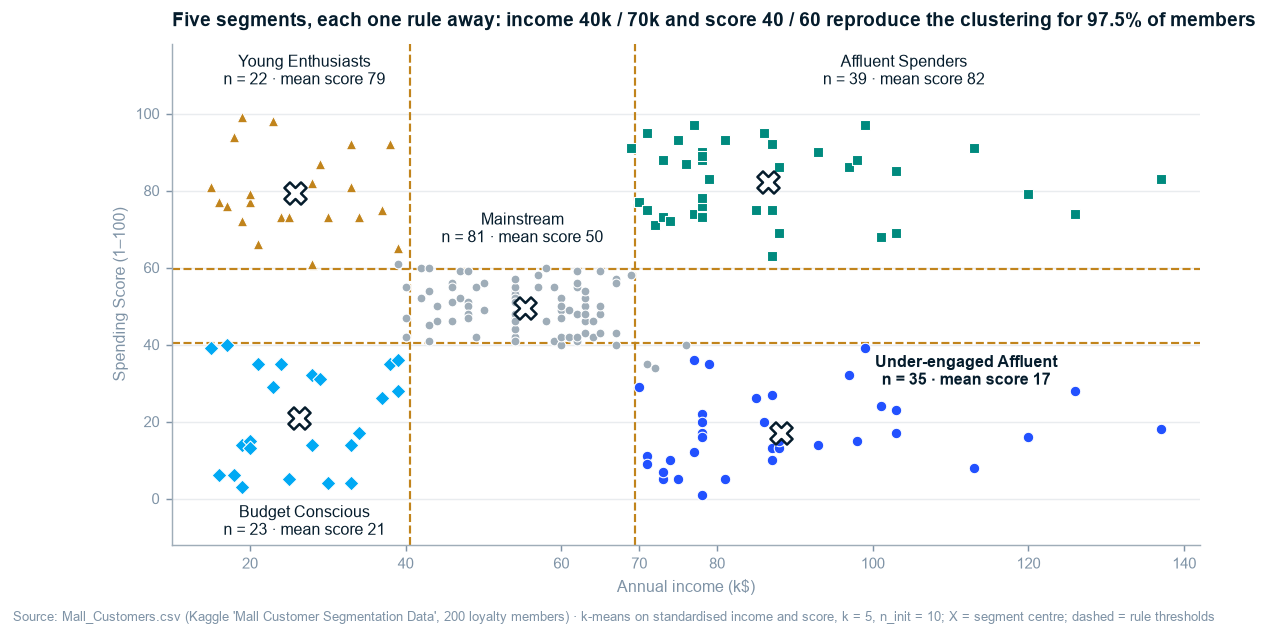

In [8]:
fig, ax = plt.subplots(figsize=(10.2, 5.0))
for x in (40.5, 69.5):
    ax.axvline(x, color=AMBER, lw=1.2, ls="--", zorder=1)
for y in (40.5, 59.5):
    ax.axhline(y, color=AMBER, lw=1.2, ls="--", zorder=1)
LABEL_AT = {"Under-engaged Affluent": (112, 33), "Affluent Spenders": (104, 111),
            "Young Enthusiasts": (27, 111), "Budget Conscious": (27, -6), "Mainstream": (55, 70)}
for seg in SEGMENTS[::-1]:
    s = df[df.segment == seg]
    ax.scatter(s.income_k, s.score, s=34 if seg != "Mainstream" else 24,
               marker=SEG_MARKERS[seg] if seg != "Mainstream" else "o", color=SEG_COLORS[seg],
               edgecolor="white", lw=0.6, zorder=3)
    c = cent.set_index("segment").loc[seg]
    ax.scatter(c.income_k, c.score, s=150, marker="X", color="white", edgecolor=NAVY, lw=1.4, zorder=4)
    lx, ly = LABEL_AT[seg]
    ax.text(lx, ly, f"{seg}\nn = {len(s)} · mean score {s.score.mean():.0f}", ha="center", va="center",
            fontsize=8.6, color=NAVY, fontweight="bold" if seg == "Under-engaged Affluent" else "normal")
ax.set_xlim(10, 142); ax.set_ylim(-12, 118)
ax.set_xticks([20, 40, 60, 70, 80, 100, 120, 140]); ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("Annual income (k$)"); ax.set_ylabel("Spending Score (1–100)")
ax.set_title("Five segments, each one rule away: income 40k / 70k and score 40 / 60 reproduce the clustering for 97.5% of members")
finish(fig, "k-means on standardised income and score, k = 5, n_init = 10; X = segment centre; dashed = rule thresholds")
save(fig, "ex07_segments.png")
plt.show()

**So What:** the clustering reduces to four numbers marketing already understands. The five members
on which rule and model disagree all sit on a border (silhouette ≤ 0.49, four of them ≤ 0.20).

**Implication:** the CRM team does not need to deploy a model. One SQL filter assigns every member of the
real base to a segment, and that query is also how the segment sizes this file cannot supply get
measured.

## 5.6 The pair construction, seen through the segments

In [9]:
par = df.groupby("segment", observed=True).id_odd.mean().rename("share_odd_id")
print(par.round(2).to_string())

segment
Under-engaged Affluent    1.00
Affluent Spenders         0.00
Young Enthusiasts         0.00
Budget Conscious          1.00
Mainstream                0.52


Each corner segment is made of **one parity only**: every Affluent Spender and Young Enthusiast has an
even ID, every Under-engaged Affluent and Budget Conscious member an odd one. That is `01` §1.5 seen
from the segment side: the high/low pairs at each income extreme were split into the two corners, so
Affluent Spenders ≈ Under-engaged Affluent in size (39 vs 35) and Young Enthusiasts ≈ Budget Conscious
(22 vs 23) **by construction**. The segment shares in §5.3 are not estimates of anything.

## 5.7 Whom to retain, whom to convert

In [10]:
uea = df[df.segment == "Under-engaged Affluent"]
asp = df[df.segment == "Affluent Spenders"]
uea_young, uea_old = uea[~uea.age_over_40], uea[uea.age_over_40]
cmp = pd.DataFrame({
    "Affluent Spenders": [len(asp), asp.income_k.mean(), asp.score.mean(), asp.age.median(), f"{asp.age.min()}–{asp.age.max()}"],
    "Under-engaged Affluent, ≤ 40": [len(uea_young), uea_young.income_k.mean(), uea_young.score.mean(), uea_young.age.median(), f"{uea_young.age.min()}–{uea_young.age.max()}"],
    "Under-engaged Affluent, > 40": [len(uea_old), uea_old.income_k.mean(), uea_old.score.mean(), uea_old.age.median(), f"{uea_old.age.min()}–{uea_old.age.max()}"],
}, index=["members", "mean income (k$)", "mean score", "median age", "age range"]).T
df["target"] = np.select([df.segment == "Affluent Spenders",
                          (df.segment == "Under-engaged Affluent") & ~df.age_over_40,
                          df.segment == "Under-engaged Affluent"],
                         ["retain", "convert pilot", "convert — low prior"], "maintain")
cmp

,members,mean income (k$),mean score,median age,age range
Affluent Spenders,39,86.538462,82.128205,32.0,27–40
"Under-engaged Affluent, ≤ 40",15,88.0,14.4,34.0,19–40
"Under-engaged Affluent, > 40",20,88.35,19.15,47.0,41–59


### Exhibit 8 — Every Affluent Spender is 27–40; only 15 of the 35 Under-engaged Affluent are in that age range

  saved reports/figures/ex08_target_age.png


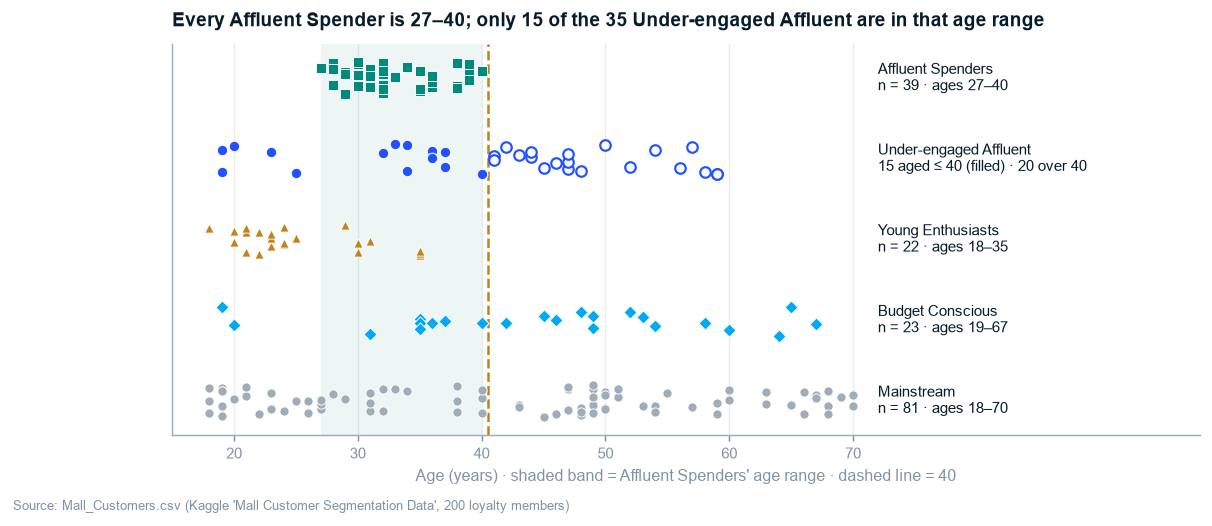

In [11]:
fig, ax = plt.subplots(figsize=(10.2, 3.9))
order = ["Affluent Spenders", "Under-engaged Affluent", "Young Enthusiasts", "Budget Conscious", "Mainstream"]
ax.axvspan(27, 40, color=TEAL, alpha=0.07, lw=0)
ax.axvline(40.5, color=AMBER, lw=1.4, ls="--")
for i, seg in enumerate(order[::-1]):
    s = df[df.segment == seg]
    y = i + rng.uniform(-0.2, 0.2, len(s))
    col = SEG_COLORS[seg]
    if seg == "Under-engaged Affluent":
        yng = ~s.age_over_40.to_numpy()
        ax.scatter(s.age[yng], y[yng], s=34, marker="o", color=BLUE, edgecolor="white", lw=0.6, zorder=3)
        ax.scatter(s.age[~yng], y[~yng], s=34, marker="o", facecolor="white", edgecolor=BLUE, lw=1.2, zorder=3)
        lbl = f"{seg}\n{yng.sum()} aged ≤ 40 (filled) · {(~yng).sum()} over 40"
    else:
        ax.scatter(s.age, y, s=26, marker=SEG_MARKERS[seg] if seg != "Mainstream" else "o",
                   color=col, edgecolor="white", lw=0.5, zorder=2)
        lbl = f"{seg}\nn = {len(s)} · ages {s.age.min()}–{s.age.max()}"
    ax.text(72, i, lbl, va="center", fontsize=8.2, color=NAVY)
ax.set_yticks([]); ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlim(15, 98); ax.set_xticks(range(20, 75, 10))
ax.set_xlabel("Age (years) · shaded band = Affluent Spenders' age range · dashed line = 40")
ax.set_title("Every Affluent Spender is 27–40; only 15 of the 35 Under-engaged Affluent are in that age range")
finish(fig)
save(fig, "ex08_target_age.png")
plt.show()

**So What:** the textbook advice is "convert the Under-engaged Affluent: they have the money but do not
spend". The data narrows it. The under-40s in that segment have the same income as the Affluent
Spenders and the same age, so their high-spending twin exists in the file. The over-40s have no
high-spending counterpart anywhere in the file, at any income (`04` §4.3).

**Implication:** the conversion pilot should start with the under-40 Under-engaged Affluent
(15 of 35 in this file). The over-40s are not written off; they get a cheaper, separate test with a lower
prior, because nothing in this data shows that their behaviour can move.

## 5.8 Fairness — gender and age

In [12]:
ct = pd.crosstab(df.segment, df.gender)
chi = stats.chi2_contingency(ct)
cramer_v = np.sqrt(chi.statistic / (len(df) * (min(ct.shape) - 1)))
tgt = df[df.target == "convert pilot"]
print(ct.assign(female_share=lambda t: (t.Female / t.sum(axis=1)).round(2)).to_string())
print(f"\nsegment × gender: χ² p = {chi.pvalue:.2f}, Cramér's V = {cramer_v:.2f}")
rest = df[df.target != "convert pilot"]
_, p_tgt_gender = stats.fisher_exact([[int(tgt.gender_female.sum()), int(len(tgt) - tgt.gender_female.sum())],
                                      [int(rest.gender_female.sum()), int(len(rest) - rest.gender_female.sum())]])
print(f"convert-pilot slice: {len(tgt)} members, {int(tgt.gender_female.sum())} female = {tgt.gender_female.mean():.0%} "
      f"(rest of file: {rest.gender_female.mean():.0%}); Fisher p = {p_tgt_gender:.2f}")

gender                  Female  Male  female_share
segment                                           
Under-engaged Affluent      16    19          0.46
Affluent Spenders           21    18          0.54
Young Enthusiasts           13     9          0.59
Budget Conscious            14     9          0.61
Mainstream                  48    33          0.59

segment × gender: χ² p = 0.69, Cramér's V = 0.11
convert-pilot slice: 15 members, 5 female = 33% (rest of file: 58%); Fisher p = 0.10


| Attribute | Finding | Decision |
|---|---|---|
| Gender | Segments do not differ by gender (χ² p ≈ 0.69, V ≈ 0.11) | No gender targeting; the rule uses income and score only |
| Gender, pilot slice | The under-40 Under-engaged Affluent are 5 of 15 female (33%) against 58% in the rest of the file. With 15 members this is within chance (Fisher p ≈ 0.10), but it is the kind of skew that can grow on a real base | Stratify the pilot's randomisation by gender and report results by gender, so an offer that only works for one group is visible |
| Age | The pilot slice is defined partly by age (≤ 40) | A deliberate, documented choice based on §4.3. It decides only the **order of testing**, not who is excluded from offers. Over-40s get their own test arm. Legal / compliance should confirm age-based campaign selection is permitted under the mall's privacy policy and local data-protection law |

## 5.9 Pilot design — what it takes to prove "convertible"

The file has no response variable, so conversion has to be measured in a randomised pilot on the
**full** loyalty base: treatment (the offer) against a holdout (no offer), randomised within segment.
The primary metric should be redemption or incremental spend from transactions, not the Spending Score.

How many members per arm? Two-sided α = 0.05, power 0.80, for a range of baseline response rates and
relative lifts:

In [13]:
power = NormalIndPower()
base_rates = [0.02, 0.05, 0.10, 0.20]
lifts = [0.25, 0.50, 1.00]
ptab = pd.DataFrame({f"+{int(l*100)}% lift": [int(np.ceil(power.solve_power(
    proportion_effectsize(p * (1 + l), p), alpha=0.05, power=0.8, ratio=1))) for p in base_rates] for l in lifts},
    index=[f"{p:.0%} baseline" for p in base_rates])
ptab.to_csv(REPORTS / "_power.csv")
n_per_arm_5_50 = int(ptab.loc["5% baseline", "+50% lift"])

n_slice = len(tgt)
h_mde = power.solve_power(nobs1=n_slice // 2, alpha=0.05, power=0.8, ratio=(n_slice - n_slice // 2) / (n_slice // 2))
mde_from_5 = float(np.sin(np.arcsin(np.sqrt(0.05)) + h_mde / 2) ** 2)
print(ptab.to_string())
print(f"\nIn-file pilot slice: {n_slice} members → {n_slice // 2} vs {n_slice - n_slice // 2}")
print(f"  smallest detectable effect (Cohen's h) = {h_mde:.2f}: a 5% response rate would have to rise to {mde_from_5:.0%}")

              +25% lift  +50% lift  +100% lift
2% baseline       13768       3789        1110
5% baseline        5318       1458         424
10% baseline       2501        681         195
20% baseline       1092        292          81

In-file pilot slice: 15 members → 7 vs 8
  smallest detectable effect (Cohen's h) = 1.45: a 5% response rate would have to rise to 66%


### Exhibit 9 — A credible pilot needs the full member base: a 50% lift on a 5% response takes ~1,460 members per arm

  saved reports/figures/ex09_power.png


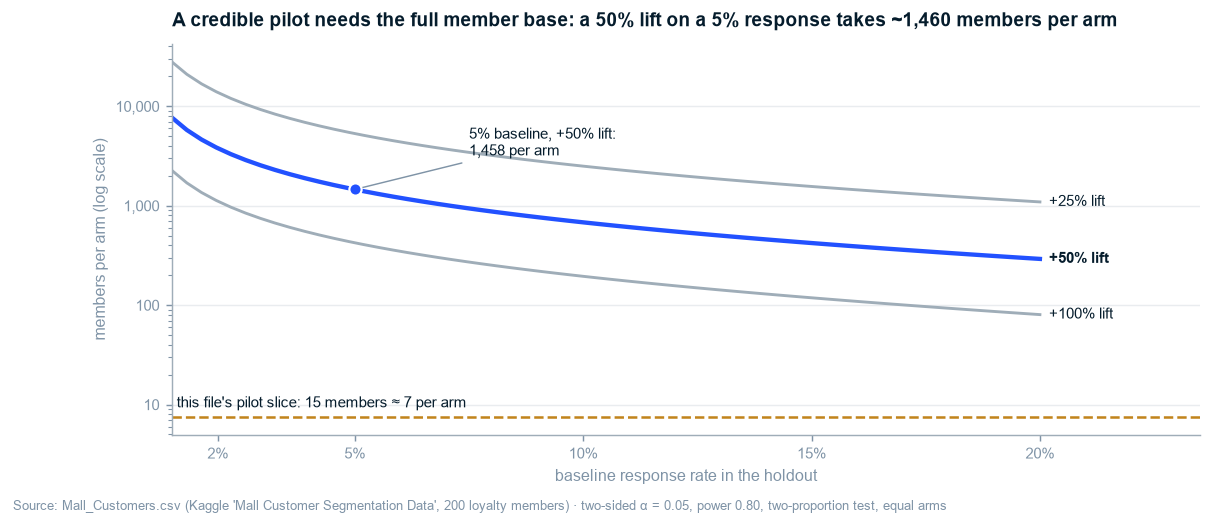

In [14]:
grid = np.linspace(0.01, 0.20, 60)
fig, ax = plt.subplots(figsize=(10.2, 3.9))
for l, col, lw in [(0.25, GREY, 1.6), (0.50, BLUE, 2.4), (1.00, GREY, 1.6)]:
    n_arm = [power.solve_power(proportion_effectsize(p * (1 + l), p), alpha=0.05, power=0.8) for p in grid]
    ax.plot(grid, n_arm, color=col, lw=lw)
    ax.text(0.202, n_arm[-1], f"+{int(l*100)}% lift", va="center", fontsize=8.5,
            color=NAVY, fontweight="bold" if l == 0.5 else "normal")
ax.set_yscale("log")
ax.axhline(n_slice / 2, color=AMBER, lw=1.4, ls="--")
ax.text(0.011, n_slice / 2 * 1.25, f"this file's pilot slice: {n_slice} members ≈ {n_slice // 2} per arm",
        fontsize=8.3, color=NAVY)
ax.scatter([0.05], [n_per_arm_5_50], s=46, color=BLUE, edgecolor="white", lw=1.2, zorder=4)
ax.annotate(f"5% baseline, +50% lift:\n{n_per_arm_5_50:,} per arm", (0.05, n_per_arm_5_50),
            xytext=(0.075, n_per_arm_5_50 * 2.2), fontsize=8.5, color=NAVY,
            arrowprops=dict(arrowstyle="-", color=SLATE, lw=0.8))
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0.01, 0.235); ax.set_xticks([0.02, 0.05, 0.10, 0.15, 0.20])
ax.set_xlabel("baseline response rate in the holdout"); ax.set_ylabel("members per arm (log scale)")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("A credible pilot needs the full member base: a 50% lift on a 5% response takes ~1,460 members per arm")
finish(fig, "two-sided α = 0.05, power 0.80, two-proportion test, equal arms")
save(fig, "ex09_power.png")
plt.show()

**So What:** the 15 members in this file could only reveal an effect that turns a 5% response into one
of about 66%, which no campaign achieves. To detect a realistic +50% lift on a 5% baseline, each arm
needs about 1,460 members drawn from the real base.

**Implication:** the pilot is sized on the mall's actual segment counts, which the rule in §5.5
produces in one query. If the real under-40 Under-engaged Affluent segment is smaller than ~3,000
members, the pilot either runs longer, accepts a larger minimum detectable lift, or pools the two
affluent age groups with age as a stratification variable.

## 5.10 Segmentation card and outputs

In [15]:
card = {
    "name": "Mall loyalty segmentation — income × spending score",
    "features": FEATURES, "excluded": ["customer_id (encodes income rank)", "age (descriptor only)", "gender (fairness check only)"],
    "scaler": {"mean": scaler.mean_.round(4).tolist(), "scale": scaler.scale_.round(4).tolist()},
    "algorithm": f"KMeans(k={K_STAR}, n_init=10, random_state={RANDOM_STATE})",
    "centroids_original_units": {r.segment: {"income_k": round(r.income_k, 1), "score": round(r.score, 1)} for r in cent.itertuples()},
    "deployable_rule": {"Affluent Spenders": "income >= 70 and score >= 60",
                        "Under-engaged Affluent": "income >= 70 and score <= 40",
                        "Young Enthusiasts": "income <= 40 and score >= 60",
                        "Budget Conscious": "income <= 40 and score <= 40", "Mainstream": "otherwise"},
    "validation": {"silhouette": round(crit.silhouette[K_STAR], 3), "null_max_silhouette": round(crit.null_max_any[K_STAR], 3),
                   "ari_gmm": round(ari_gmm, 3), "ari_ward": round(ari_ward, 3),
                   "bootstrap_jaccard_min": round(jac.jaccard_mean.min(), 3), "rule_agreement": round(agree, 3)},
    "limits": ["segment sizes in the training file are generator artifacts (paired construction) — re-measure on the real base",
               "Spending Score is mall-defined and not an outcome; segments describe current behaviour, not response",
               "thresholds are in the training file's units (k$, score 1–100); re-check if the score formula changes",
               "single n_init=1 runs are unstable; keep n_init >= 10"],
}
(MODELS / "segmentation_card.json").write_text(json.dumps(card, indent=1))
df.to_parquet(PROC / "mall_segmented.parquet", index=False)
profile.round(4).to_csv(REPORTS / "_segment_profile.csv")
robust.to_csv(REPORTS / "_robustness.csv", index=False)
print("saved models/segmentation_card.json, data/processed/mall_segmented.parquet, reports/_segment_profile.csv")

P = profile
kf_update(
    k_star=K_STAR, k_winners=winners, ch_gain_k5=float(ch_gain[K_STAR]), silhouette_k5=float(crit.silhouette[5]),
    silhouette_by_k={int(k): float(v) for k, v in crit.silhouette.items()},
    null_max_k5=float(crit.null_max_any[5]), null_unif_p975_k5=float(crit["null_uniform_p97.5"][5]),
    null_indep_p975_k5=float(crit["null_indep_p97.5"][5]),
    silhouette_3d_best=float(best3),
    seg_n={s: int(P.loc[s, "n"]) for s in SEGMENTS}, seg_share={s: float(P.loc[s, "share"]) for s in SEGMENTS},
    seg_income={s: float(P.loc[s, "income_mean"]) for s in SEGMENTS}, seg_score={s: float(P.loc[s, "score_mean"]) for s in SEGMENTS},
    seg_age_median={s: float(P.loc[s, "age_median"]) for s in SEGMENTS},
    seg_age_min={s: int(P.loc[s, "age_min"]) for s in SEGMENTS}, seg_age_max={s: int(P.loc[s, "age_max"]) for s in SEGMENTS},
    seg_female={s: float(P.loc[s, "female"]) for s in SEGMENTS},
    seg_share_odd={s: float(par[s]) for s in SEGMENTS},
    seed_ari_min=float(min(seed_ari)), single_init_fail=float(np.mean(np.array(single) < 0.99)),
    ari_gmm=float(ari_gmm), ari_ward=float(ari_ward), ari_wo_outliers=float(ari_wo_outliers), ari_quadrant=float(ari_quadrant),
    jaccard_min=float(jac.jaccard_mean.min()), jaccard_max=float(jac.jaccard_mean.max()),
    n_borderline=int((df.silhouette < 0.25).sum()),
    rule_agreement=float(agree), rule_ari=float(ari_rule), n_rule_disagree=int((df.segment_rule != df.segment.astype(str)).sum()),
    tree_cv_acc={int(d): float(v) for d, v in tree_acc.items()},
    n_uea_young=len(uea_young), n_uea_old=len(uea_old),
    uea_young_income=float(uea_young.income_k.mean()), uea_old_income=float(uea_old.income_k.mean()),
    uea_young_age_median=float(uea_young.age.median()), uea_old_age_median=float(uea_old.age.median()),
    gender_seg_p=float(chi.pvalue), gender_seg_v=float(cramer_v), pilot_female=float(tgt.gender_female.mean()),
    pilot_n_female=int(tgt.gender_female.sum()), rest_female=float(rest.gender_female.mean()), pilot_gender_p=float(p_tgt_gender),
    power_table={i: {c: int(ptab.loc[i, c]) for c in ptab.columns} for i in ptab.index},
    n_per_arm_5_50=n_per_arm_5_50, pilot_slice_n=n_slice, pilot_mde_h=float(h_mde), pilot_mde_from_5=mde_from_5,
)

saved models/segmentation_card.json, data/processed/mall_segmented.parquet, reports/_segment_profile.csv
  _key_figures.json <- k_star, k_winners, ch_gain_k5, silhouette_k5, silhouette_by_k, null_max_k5, null_unif_p975_k5, null_indep_p975_k5, silhouette_3d_best, seg_n, seg_share, seg_income, seg_score, seg_age_median, seg_age_min, seg_age_max, seg_female, seg_share_odd, seed_ari_min, single_init_fail, ari_gmm, ari_ward, ari_wo_outliers, ari_quadrant, jaccard_min, jaccard_max, n_borderline, rule_agreement, rule_ari, n_rule_disagree, tree_cv_acc, n_uea_young, n_uea_old, uea_young_income, uea_old_income, uea_young_age_median, uea_old_age_median, gender_seg_p, gender_seg_v, pilot_female, pilot_n_female, rest_female, pilot_gender_p, power_table, n_per_arm_5_50, pilot_slice_n, pilot_mde_h, pilot_mde_from_5  (126 figures total)


## Stage 4–6 — Gate Checklist (adapted for unsupervised work)

- [x] Feature decisions documented with rationale (income + score; age tested and rejected as an input; ID barred)
- [x] No leakage: no ID-derived column in any feature set (asserted)
- [x] k chosen by three of four criteria (the fourth makes its largest gain there) and tested against two no-structure nulls
- [x] Compared against a baseline (median-split quadrants) and two other algorithms
- [x] Stability: seeds, single-init failure rate, bootstrap Jaccard, outlier removal
- [x] Business translation: a two-threshold rule (97.5% agreement), named retain / convert targets, a pilot sample size
- [x] Limitations documented in `models/segmentation_card.json` · [x] Seeds fixed (`RANDOM_STATE = 42`)
- [x] Fairness: gender independent of segment; pilot-slice gender skew reported and handled by stratification; age use documented and scoped to test order